In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [31]:
raw = pd.read_csv('Telco-Customer-Churn.csv')
churn = raw['Churn']
data = raw.drop(['Churn', 'customerID'],axis=1)

In [ ]:
num_cols = data.select_dtypes(include=np.number).columns
cat_cols = data.select_dtypes(include='str').columns

print(num_cols)
print(cat_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='str')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'TotalCharges'],
      dtype='str')


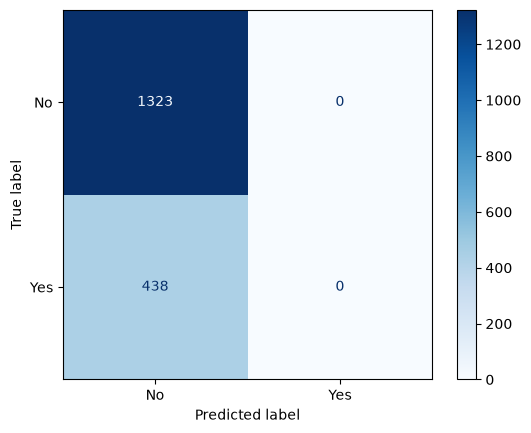

In [56]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

gender = data[['gender']]
cat_transformer = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer(transformers=[('cat',cat_transformer,['gender'])])
model = Pipeline(steps=[('preprocessor', preprocessor),('classifier',LogisticRegression(random_state=0))])
X_train,X_val,y_train,y_val = train_test_split(gender,churn)
model.fit(X_train,y_train)
predictions=model.predict(X_val)

ConfusionMatrixDisplay.from_predictions(
    y_true=y_val, 
    y_pred=predictions,
    cmap=plt.cm.Blues
)

In [11]:
print(data.shape)
print(data.info())

(7043, 20)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


[[1163  135]
 [ 250  213]]


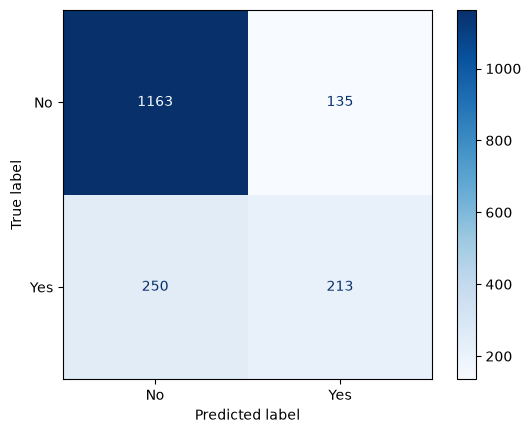

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X = data[num_cols]
y = churn
X_train, X_val, y_train, y_val = train_test_split(X,y, random_state=0)
model = LogisticRegression(random_state=0)
model.fit(X=X_train,y=y_train)
y_pred=model.predict(X_val)
print(confusion_matrix(y_true=y_val, y_pred=y_pred))
ConfusionMatrixDisplay.from_predictions(
    y_true=y_val, 
    y_pred=y_pred,
    cmap=plt.cm.Blues
)